# Examples of sample-based cell image generation

In [1]:
# for 
import numpy as np
import matplotlib.pyplot as plt
from data_generator.default.synthetic_generator import fluorescent_sampler, texture_mask
from tifffile import imread

import os
import sys
import re

main_dir = '/'
for s in os.getcwd().split('/')[:-1]:
    if s != '':
        main_dir += s+'/'
if main_dir not in sys.path:
    (sys.path).append(main_dir)

from skimage.measure import find_contours

### Load Data

In [2]:
img = imread(f'{main_dir}Fluo-C3DH-H157/02/t052.tif')
img = ((img-img.mean())/img.std())[46] # normalise and take labelled slice
labels = imread(f'{main_dir}Fluo-C3DH-H157/02_GT/SEG/man_seg_052_046.tif')

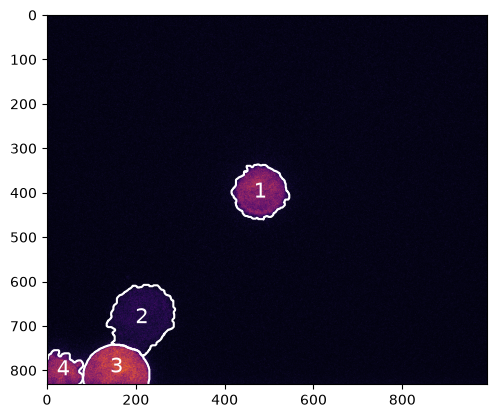

In [3]:
fig = plt.figure()
ax = plt.subplot()

ax.imshow(img, cmap='inferno')
X, Y = np.meshgrid(np.arange(img.shape[0]), np.arange(img.shape[1]), indexing='ij')

for v in np.unique(labels[labels>0]):
    contours = find_contours((labels==v).astype(int), .5)
    for contour in contours:
        ax.plot(contour[:,1], contour[:,0], 'w')

        xc, yc = np.mean(X[labels==v]), np.mean(Y[labels==v])

        ax.annotate(v, (yc, xc), fontsize=15,
                    va='center', ha='center', color='w')
    

plt.show()

### Sample Fluorescence

In [4]:
help(fluorescent_sampler)

Help on function fluorescent_sampler in module data_generator.default.synthetic_generator:

fluorescent_sampler(image, instances, sampling=(1.0, 1.0, 1.0), dx=2, min_dist=-50, max_dist=50, save_path=None, subsample=5, disable_labels=False)
    Fluorescent Sampler for generating sample-based synthetic cell images.

    Converts labelled images/volumes into 'sampler' for image generator. 2D and 3D input supported!

    image: array source of intensities used to sample.
    instances: bool or int array of image labels.
    sampling: pixel/voxel size used to calculate distance maps.
    dx: value interval width for sampling.
    min_dist, max_dist: values that define the range of sampling.
    subsample: int, rate to subsample intensity values in defined intervals.
    save_path: Optional, path to save sampler.

    Note: The range [min_dist, max_dist] with interval width 'dx' must include 0.



In [5]:
# dx = .5 # recommended
dx = 2 # for illustration
sampling = (0.5, 0.126, 0.126)

sampler = fluorescent_sampler(img, labels, sampling=sampling[1:], dx=dx, min_dist=-8.0, max_dist=10.0, subsample=2)

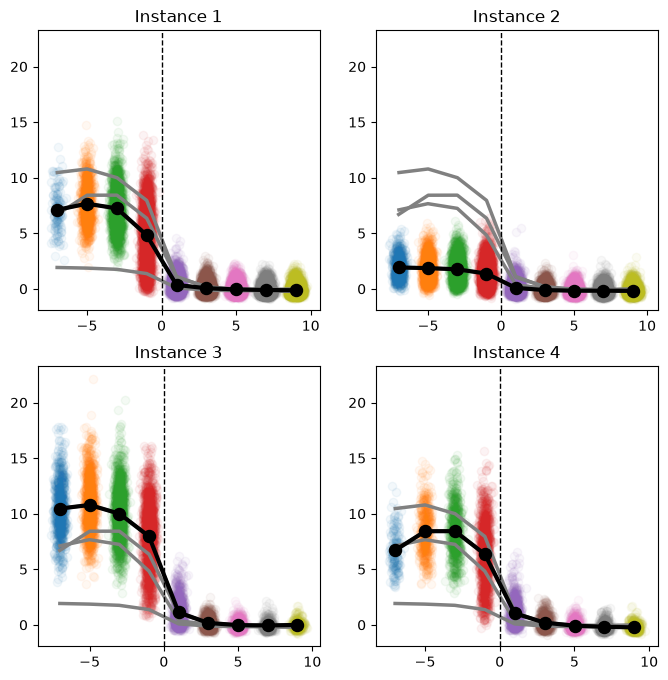

In [6]:
fig, axes = plt.subplots(2,2,figsize=(8,8))

for v, ax in zip(np.unique(labels[labels>0]), axes.flatten()):
    ax.set_title(f'Instance {v}')

    xl, yl = [], []
    for s in sampler[str(v)]:

        # sampling interval
        lb, ub = sampler[str(v)][s]['x0'], sampler[str(v)][s]['x1']
        ub = lb + dx if sampler[str(v)][s]['x1'] > 500 else ub
        lb = ub - dx if sampler[str(v)][s]['x0'] < -500 else lb
        
        y = sampler[str(v)][s]['y']
        x = (lb+ub)/2 * np.ones(len(y)) + np.random.normal(scale=dx/10, size=len(y))

        ax.scatter(x, y, alpha=0.05, zorder=-1)
        ax.scatter(np.mean(x), np.mean(y), alpha=1, s=75, color='k', zorder=2)

        xl.append(np.mean(x)); yl.append(np.mean(y))

    ax.plot(xl, yl, 'k', lw=3, zorder=2)
    for tmp in axes.flatten():
        tmp.plot(xl, yl, 'grey', lw=2.5, zorder=1)

ylim = np.array([ax.get_ylim() for ax in axes.flatten()])
for ax in axes.flatten():
    ax.set_ylim([min(ylim[:,0]), max(ylim[:,1])])
    ax.plot([0,0], [min(ylim[:,0]), max(ylim[:,1])], 'k--', lw=1)

plt.show()

## 1.1) Intervals

## 1.2) Distance

## 1.3) Distance Map Noise

## 2.1) Distance

## 2.2) Voronoi Patterns

## 2.3) Variations

Each intensity value is stored based on the distance interval (separate colours). We sample the signals and local environment of each instance in the real data independently - giving us the freedom to create a range of synthetic cell images with different arrangements (See below). 

### Generate Synthetic Image

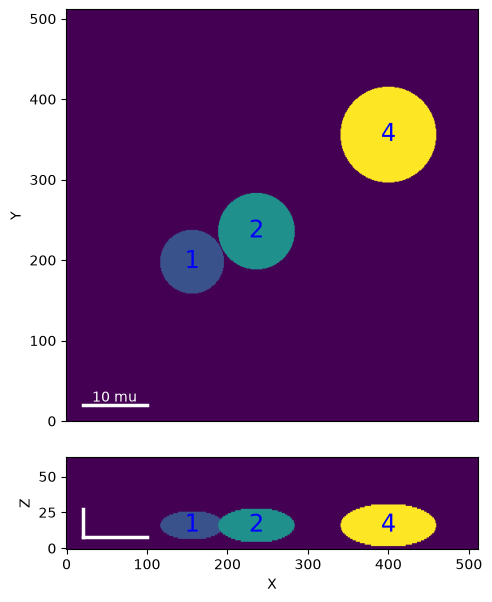

In [11]:
scale = 1.25
fig = plt.figure(figsize=(4*scale,5*scale))
rows = 5
ax0 = plt.subplot2grid((rows,1), (0,0), rowspan=rows-1)
ax1 = plt.subplot2grid((rows,1), (rows-1,0), rowspan=1)

zres, xres, yres = 64, 512, 512
Z, X, Y = np.meshgrid(np.arange(zres), np.arange(xres), np.arange(yres), indexing='ij')

# spheres as cells. Obviously want more cell-like shapes in real implementation
# [[Z, X, Y]]
locs = [[16, 198, 156],
        [16, 236, 236],
        [16, 356, 400]] # in pixels
radii = [5.0, 6.0, 7.5] # in mu
labs = [1,2,4] # to match data (kept random in real implementation)

synth_instances = np.zeros([zres, xres, yres],int)
for loc, r, v in zip(locs, radii, labs):
    cell = np.sqrt((sampling[0]*(Z-loc[0]))**2 + 
                   (sampling[1]*(X-loc[1]))**2 + 
                   (sampling[2]*(Y-loc[2]))**2) < r
    synth_instances[cell] = v

    ax0.annotate(v, (np.mean(Y[cell]), np.mean(X[cell])), color='b', 
                 zorder=5, va='center', ha='center', fontsize=17.5)
    ax1.annotate(v, (np.mean(Y[cell]), np.mean(Z[cell])), color='b', 
                 zorder=5, va='center', ha='center', fontsize=17.5)


ax0.imshow(synth_instances.max(axis=0), zorder=-1, origin='lower')
ax1.imshow(synth_instances.max(axis=1), aspect='auto', zorder=-1, origin='lower')

ax0.set_xticks([])
ax0.set_ylabel('Y'); ax1.set_xlabel('X'); ax1.set_ylabel('Z'); 

# add scale bars
d = 10
z0,x0,y0 = 7.5, 20, 20
ax0.plot([x0, x0+d/sampling[1]], [y0, y0], color='w', lw=2.5)
ax1.plot([x0, x0+d/sampling[1]], [z0, z0], color='w', lw=2.5)
ax1.plot([x0, x0], [z0, z0+d/sampling[0]], color='w', lw=2.5)
ax0.annotate('10 mu', (x0+d/(2*sampling[1]), y0), color='w', va='bottom', ha='center')

fig.tight_layout()
plt.show()

In [12]:
help(texture_mask)

Help on function texture_mask in module data_generator.default.synthetic_generator:

texture_mask(instances, sampler, sampling=(1.0, 1.0, 1.0), dist_map=None, dm_noise=None, vm_noise=None, fix_instances=False)
    Generate Sample-based cell images with texture_mask

    Takes sampler obj. from fluorescent_sampler and generates textured image with instances provided.

    instances: bool or int array of image labels used to guide sampling.
    sampler: obj. saved from fluorescent_sampler
    sampling: pixel/voxel size used to calculate distance maps. Can be different to source img.
    dist_map: float array, signed distance map of instances (negative inside).
    dm_noise: float, standard deviation of additive gaussian noise for distance map. Reduces block-y
              appearance. If None, no noise added.
    vm_noise: float, standard deviation of additive gaussian noise for voronoi map. Reduces block-y
              appearance between cells. If None, no noise added.



In [13]:
synthetic_image = texture_mask(synth_instances, sampler, sampling=sampling, dm_noise=1, vm_noise=10, fix_instances=True)

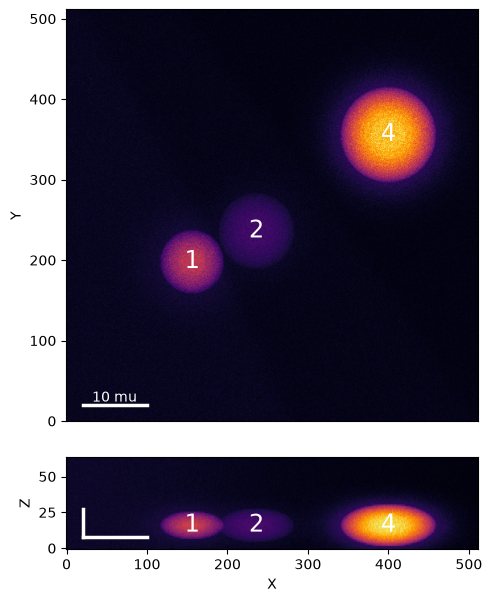

In [14]:
fig = plt.figure(figsize=(4*scale,5*scale))
rows = 5
ax0 = plt.subplot2grid((rows,1), (0,0), rowspan=rows-1)
ax1 = plt.subplot2grid((rows,1), (rows-1,0), rowspan=1)

for loc, r, v in zip(locs, radii, labs):
    cell = np.sqrt((sampling[0]*(Z-loc[0]))**2 + 
               (sampling[1]*(X-loc[1]))**2 + 
               (sampling[2]*(Y-loc[2]))**2) < r
    ax0.annotate(v, (np.mean(Y[cell]), np.mean(X[cell])), color='w', 
                 zorder=5, va='center', ha='center', fontsize=17.5)
    ax1.annotate(v, (np.mean(Y[cell]), np.mean(Z[cell])), color='w', 
                 zorder=5, va='center', ha='center', fontsize=17.5)


ax0.imshow(synthetic_image.mean(axis=0), zorder=-1, cmap='inferno', origin='lower')
ax1.imshow(synthetic_image.mean(axis=1), aspect='auto', zorder=-1, cmap='inferno', origin='lower')

ax0.set_xticks([])
ax0.set_ylabel('Y'); ax1.set_xlabel('X'); ax1.set_ylabel('Z'); 

# add scale bars
d = 10
z0,x0,y0 = 7.5, 20, 20
ax0.plot([x0, x0+d/sampling[1]], [y0, y0], color='w', lw=2.5)
ax1.plot([x0, x0+d/sampling[1]], [z0, z0], color='w', lw=2.5)
ax1.plot([x0, x0], [z0, z0+d/sampling[0]], color='w', lw=2.5)
ax0.annotate('10 mu', (x0+d/(2*sampling[1]), y0), color='w', va='bottom', ha='center')

fig.tight_layout()
plt.show()

### Augmentation

In [15]:
from utils import ElasticPerlinTransform, speckle_transform

In [16]:
help(ElasticPerlinTransform)

Help on class ElasticPerlinTransform in module utils.ept_transform:

class ElasticPerlinTransform(builtins.object)
 |  ElasticPerlinTransform(prob: float = 0.25, grid_points: int = 8, p: float = 0.05, sf: int = 2, order: int = 3)
 |
 |  Elastic Deformation using Perlin noise to generate smooth distortion.
 |
 |  Inspired by
 |  Elastic deformation of images as described in Simard, 2003
 |  (DOI 10.1109/ICDAR.2003.1227801)
 |
 |  ** Currently only supports 3D Images **
 |
 |  Args:
 |      prob: probability (between 0 and 1) with which to perform this
 |          augmentation. The input is returned unmodified with a probability
 |          of ``1 - prob``
 |      grid_points:
 |      p: distortion amplitude as a fraction of resolution
 |
 |  Important:
 |      Since the amplitude of the change is relative to the input
 |      resolution, anisotropic factor is accounted for.
 |
 |  Methods defined here:
 |
 |  __call__(self, inp, targets)
 |      Call self as a function.
 |
 |  __init__(

In [24]:
# Deform Labels

T1 = ElasticPerlinTransform(prob=1, grid_points=[1,8,8], p=0.05, sf=2)

new_synth_instances = T1(synth_instances[np.newaxis], [])[0][0]

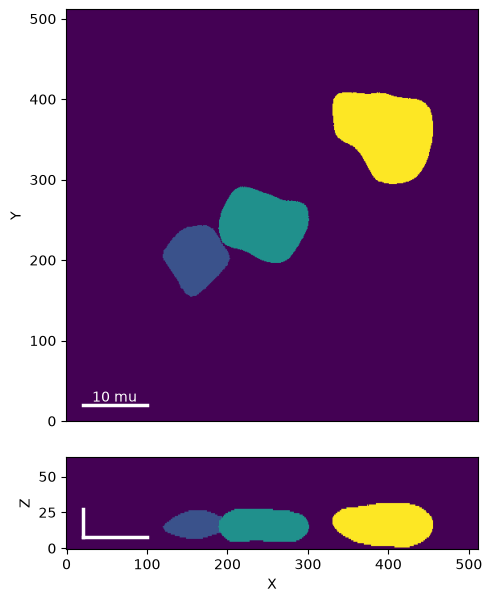

In [25]:
fig = plt.figure(figsize=(4*scale,5*scale))
rows = 5
ax0 = plt.subplot2grid((rows,1), (0,0), rowspan=rows-1)
ax1 = plt.subplot2grid((rows,1), (rows-1,0), rowspan=1)

ax0.imshow(new_synth_instances.max(axis=0), zorder=-1, origin='lower')
ax1.imshow(new_synth_instances.max(axis=1), aspect='auto', zorder=-1, origin='lower')

ax0.set_xticks([])
ax0.set_ylabel('Y'); ax1.set_xlabel('X'); ax1.set_ylabel('Z'); 

# add scale bars
d = 10
z0,x0,y0 = 7.5, 20, 20
ax0.plot([x0, x0+d/sampling[1]], [y0, y0], color='w', lw=2.5)
ax1.plot([x0, x0+d/sampling[1]], [z0, z0], color='w', lw=2.5)
ax1.plot([x0, x0], [z0, z0+d/sampling[0]], color='w', lw=2.5)
ax0.annotate('10 mu', (x0+d/(2*sampling[1]), y0), color='w', va='bottom', ha='center')

fig.tight_layout()
plt.show()

ElasticPerlinTransform replaces the vector field in the standard 'Elastic Deformation' with Perlin noise. Controlling the wavelength and amplitude of the perlin noise, we can create deformations similar to those observed in cell imaging. 

In [26]:
new_synthetic_image = texture_mask(new_synth_instances, sampler, sampling=sampling, dm_noise=1, vm_noise=10, fix_instances=True)

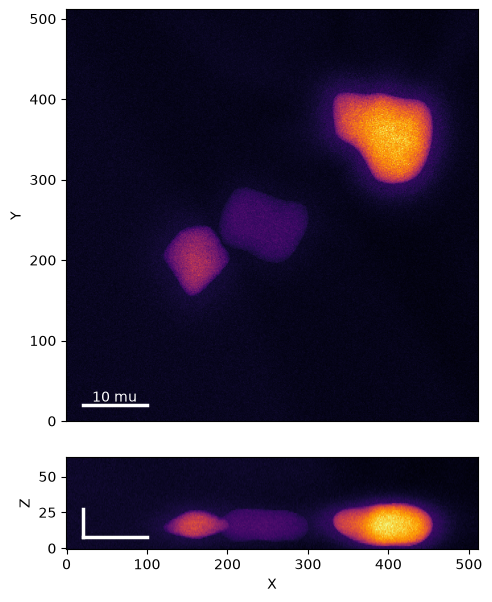

In [27]:
fig = plt.figure(figsize=(4*scale,5*scale))
rows = 5
ax0 = plt.subplot2grid((rows,1), (0,0), rowspan=rows-1)
ax1 = plt.subplot2grid((rows,1), (rows-1,0), rowspan=1)


ax0.imshow(new_synthetic_image.mean(axis=0), zorder=-1, cmap='inferno', origin='lower')
ax1.imshow(new_synthetic_image.mean(axis=1), aspect='auto', zorder=-1, cmap='inferno', origin='lower')

ax0.set_xticks([])
ax0.set_ylabel('Y'); ax1.set_xlabel('X'); ax1.set_ylabel('Z'); 

# add scale bars
d = 10
z0,x0,y0 = 7.5, 20, 20
ax0.plot([x0, x0+d/sampling[1]], [y0, y0], color='w', lw=2.5)
ax1.plot([x0, x0+d/sampling[1]], [z0, z0], color='w', lw=2.5)
ax1.plot([x0, x0], [z0, z0+d/sampling[0]], color='w', lw=2.5)
ax0.annotate('10 mu', (x0+d/(2*sampling[1]), y0), color='w', va='bottom', ha='center')

fig.tight_layout()
plt.show()

In [28]:
help(speckle_transform)

Help on function speckle_transform in module utils.speckle_transform:

speckle_transform(image, alpha, p, mask=None, sigma=1, sf=2, per_instance=False, wavelengths=[[2, 3, 4], [2, 3, 4]])
    Applies speckle scaling to image.

    image: 2-D or 3-D image array

    alpha: amplitude of positive scaling
    p: fraction of pixels to apply positive scaling
    sigma: smoothing parameter for scaled regions
    sf: speed up 3D perlin noise gen (default 2)
    per instance: Apply scaling per instance

    wavelengths: List of wavelengths to sample in z, and xy direction (eg. [[1,2], [3,4,5,6]])

    < within function >
    dI_0: amplitude of negative scaling *
    p0: fraction of pixels to apply negative scaling *

    * calculated such that net scaling = 1

    if mask is not None -> apply positive scaling to mask=1 regions only



In [34]:
# Intensity augmentation

aug_synthetic_image = speckle_transform(new_synthetic_image, 1.75, 0.2, mask=new_synth_instances, sigma=2.5, wavelengths=[[2],[4,5]])

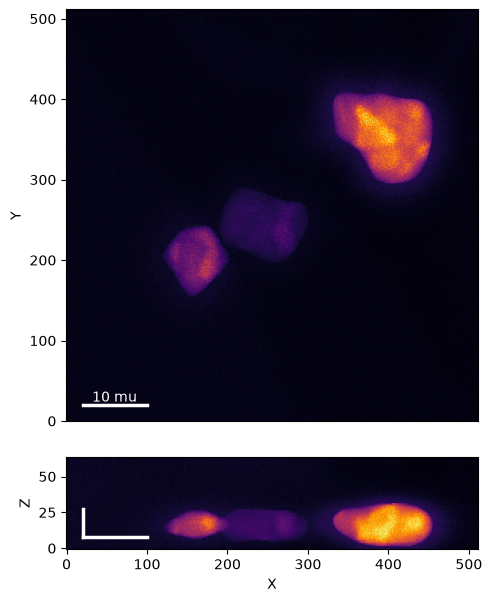

In [35]:
fig = plt.figure(figsize=(4*scale,5*scale))
rows = 5
ax0 = plt.subplot2grid((rows,1), (0,0), rowspan=rows-1)
ax1 = plt.subplot2grid((rows,1), (rows-1,0), rowspan=1)


ax0.imshow(aug_synthetic_image.mean(axis=0), zorder=-1, cmap='inferno', origin='lower')
ax1.imshow(aug_synthetic_image.mean(axis=1), aspect='auto', zorder=-1, cmap='inferno', origin='lower')

ax0.set_xticks([])
ax0.set_ylabel('Y'); ax1.set_xlabel('X'); ax1.set_ylabel('Z'); 

# add scale bars
d = 10
z0,x0,y0 = 7.5, 20, 20
ax0.plot([x0, x0+d/sampling[1]], [y0, y0], color='w', lw=2.5)
ax1.plot([x0, x0+d/sampling[1]], [z0, z0], color='w', lw=2.5)
ax1.plot([x0, x0], [z0, z0+d/sampling[0]], color='w', lw=2.5)
ax0.annotate('10 mu', (x0+d/(2*sampling[1]), y0), color='w', va='bottom', ha='center')

fig.tight_layout()
plt.show()

'speckling_transform' used general, biologically realistic patterns using Perlin noise to scale the intensity values. Here a small fraction (20%) of the foreground pixels are multiplied by 1.75x. Then, a complimentary pattern is generated to gently decrease the value of 80% of pixels, keeping the intensity distribution similar to real data. NOTE: 20% are increased, 80% are decrease, but its not one or the other - a pixel can be increased, decreased, both or neither!